# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:**

Устройство — Apple M3 Max, ускоритель MPS; Python 3.13.2, PyTorch 2.15.0, ultralytics 8.4.216. Модель — YOLO26n, датасет — [BCCD](https://github.com/Shenggan/BCCD_Dataset), лицензия MIT. Выполнены разделы 1–5 и бонусы 6.3 и 6.5; бонусы 6.1, 6.2 и 6.4 не выбраны. Финальный последовательный запуск выполнен с FAST_MODE = False, выводы ячеек сохранены, ошибок выполнения нет. Источники: [датасет BCCD](https://github.com/Shenggan/BCCD_Dataset); [документация YOLO26](https://docs.ultralytics.com/models/yolo26/); [настройки обучения](https://docs.ultralytics.com/modes/train/); [лицензирование Ultralytics](https://www.ultralytics.com/license).


In [40]:
%pip install scipy


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [41]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util
import importlib.metadata
import subprocess
import sys
if importlib.util.find_spec('ultralytics') is None or importlib.metadata.version('ultralytics') != '8.4.216':
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.216'], check=True)

import csv
import hashlib
import io
import json
import math
import os
import random
import shutil
import time
import urllib.request
import xml.etree.ElementTree as ET
import zipfile
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage
from IPython.display import Markdown, display
import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
try: # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass
DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')


ultralytics 8.4.216, torch 2.15.0, device: mps


In [42]:
FAST_MODE = False # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.3', '6.5'} # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}
SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64 # сколько картинок train берется в FAST_MODE
WORKERS = 0 if os.name == 'nt' else 2 # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()


Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [43]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны


    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета

    kw.setdefault('nms', False)
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out


---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [44]:
WEIGHTS = 'yolo26n.pt' # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS) # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)
n_params = sum(p.numel() for p in model_coco.model.parameters())

def synchronize_device():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elif DEVICE == 'mps':
        torch.mps.synchronize()

def measure_latency(model, image, repeats=20, **kwargs):
    for _ in range(3):
        model.predict(image, imgsz=IMGSZ, device=DEVICE, verbose=False, nms=False, **kwargs)
    synchronize_device()
    start = time.perf_counter()
    for _ in range(repeats):
        model.predict(image, imgsz=IMGSZ, device=DEVICE, verbose=False, nms=False, **kwargs)
    synchronize_device()
    return 1000 * (time.perf_counter() - start) / repeats

latency = measure_latency(model_coco, np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8))
MODEL_INFO = dict(ultralytics=ultralytics.__version__, weights=weights_path.name,
                  sha256=hashlib.sha256(weights_path.read_bytes()).hexdigest(),
                  size_mb=weights_path.stat().st_size / 1024**2, params=n_params,
                  n_classes_coco=len(model_coco.names), latency_ms=latency)
print(json.dumps(MODEL_INFO, indent=2))


{
  "ultralytics": "8.4.216",
  "weights": "yolo26n.pt",
  "sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef",
  "size_mb": 5.287602424621582,
  "params": 2572280,
  "n_classes_coco": 80,
  "latency_ms": 6.978687504306436
}


In [45]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO


{'ultralytics': '8.4.216',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.287602424621582,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 6.978687504306436}

**Ответ:**

Выбрана YOLO26n: небольшой размер подходит для BCCD и ограниченного бюджета обучения; фактически обучение на M3 Max заняло 474.0 с. До первого predict подсчитано 2,572,280 параметров; исходный файл весов занимает 5.29 МиБ, измеренная задержка полного predict при входе 640 × 640 — 6.98 мс на MPS (3 прогрева, среднее по 20 запускам). Веса обучены на 80 классах COCO; версия ultralytics — 8.4.216, sha256 — `9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef`.

В [таблице Ultralytics](https://docs.ultralytics.com/models/yolo26/) для YOLO26n / YOLO26s приведены 2.4 / 9.5 млн параметров, COCO mAP50–95 40.9 / 48.6 для one-to-many и 40.1 / 47.8 для end-to-end, скорость T4 TensorRT 1.7 / 2.5 мс. Размер s потенциально точнее, но требует больше ресурсов; для 254 обучающих изображений выбран n. Задержки TensorRT на T4 и полного PyTorch predict на MPS напрямую не сопоставляются.

Код и веса распространяются по AGPL-3.0: при распространении необходимо сохранять лицензию и предоставлять соответствующий исходный код; при сетевом использовании изменённой программы её пользователям также должен быть доступен исходный код.


## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [46]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone']) # первые n_backbone слоев - backbone, последний - Detect
    return dict(backbone=sum(p.numel() for layer in layers[:n_backbone] for p in layer.parameters()),
                neck=sum(p.numel() for layer in layers[n_backbone:-1] for p in layer.parameters()),
                head=sum(p.numel() for p in layers[-1].parameters()))


def head_inputs_and_output(det_model, imgsz=640):
    # -> (список форм карт признаков на входе Detect, выход модели на нулевом входе 1 x 3 x imgsz x imgsz)
    feature_shapes = []
    def capture(module, args):
        feature_shapes.extend(tuple(x.shape) for x in args[0])
    handle = det_model.model[-1].register_forward_pre_hook(capture)
    was_training = det_model.training
    parameter = next(det_model.parameters())
    try:
        det_model.eval()
        with torch.inference_mode():
            output = det_model(torch.zeros(1, 3, imgsz, imgsz, device=parameter.device, dtype=parameter.dtype))
    finally:
        handle.remove()
        det_model.train(was_training)
    return feature_shapes, output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__


In [47]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)


{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [48]:
print(shapes(out))


[(1, 84, 8400), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]


**Ответ:**

Backbone извлекает признаки изображения: 1 365 472 параметра, 53.1% от 2 572 280. Neck объединяет карты со stride 8, 16 и 32, сочетая детали и контекст: 897 152 параметра, 34.9%. Head предсказывает границы рамок и оценки классов для каждой позиции: 309 656 параметров, 12.0%.

При входе 640 × 640 на Detect поступают тензоры (1, 64, 80, 80), (1, 128, 40, 40) и (1, 256, 20, 20); число позиций равно 80² + 40² + 20² = 8400. В диагностическом прямом проходе получен выход (1, 84, 8400): четыре координаты и 80 оценок классов; во вложенном словаре обе ветки имеют boxes (1, 4, 8400) и scores (1, 80, 8400).

Anchor-free означает предсказание рамок относительно точек карт признаков без заранее заданного набора прямоугольников разных размеров. В обучении one2many допускает несколько положительных предсказаний на объект, one2one обучается одному предсказанию на объект; стандартная end-to-end ветка использует one2one и обходится без NMS.


---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [49]:
DATASET_COMMIT = 'd272fb14cdff6e473fafeeeba32aba5f560e9e43'
DATASET_URL = f'https://codeload.github.com/Shenggan/BCCD_Dataset/zip/{DATASET_COMMIT}'
DATASET_NAME = 'BCCD; https://github.com/Shenggan/BCCD_Dataset; MIT'
CLASSES = ['RBC', 'WBC', 'Platelets']
source_root = DATA_ROOT / f'BCCD_Dataset-{DATASET_COMMIT}'
if not source_root.exists():
    DATA_ROOT.mkdir(exist_ok=True)
    with urllib.request.urlopen(DATASET_URL, timeout=120) as response:
        archive = response.read()
    with zipfile.ZipFile(io.BytesIO(archive)) as bundle:
        bundle.extractall(DATA_ROOT)

cleaning = Counter()
all_records = []
seen_images = set()
for xml_path in sorted((source_root / 'BCCD' / 'Annotations').glob('*.xml')):
    node = ET.parse(xml_path).getroot()
    image_path = source_root / 'BCCD' / 'JPEGImages' / node.findtext('filename')
    with Image.open(image_path) as image:
        width, height = image.size
    digest = hashlib.sha256(image_path.read_bytes()).hexdigest()
    if digest in seen_images:
        cleaning['duplicate_images'] += 1
        continue
    seen_images.add(digest)
    boxes, labels = [], []
    for obj in node.findall('object'):
        bb = obj.find('bndbox')
        box = np.array([float(bb.findtext(k)) for k in ('xmin', 'ymin', 'xmax', 'ymax')])
        original = box.copy()
        box[[0, 2]] = np.clip(box[[0, 2]], 0, width)
        box[[1, 3]] = np.clip(box[[1, 3]], 0, height)
        cleaning['clipped_boxes'] += int(not np.array_equal(original, box))
        if box[2] <= box[0] or box[3] <= box[1]:
            cleaning['removed_boxes'] += 1
            continue
        boxes.append(box)
        labels.append(CLASSES.index(obj.findtext('name')))
    all_records.append(dict(image=image_path, width=width, height=height,
                            boxes=np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
                            labels=np.asarray(labels, dtype=np.int64)))
assert len(all_records) >= 150
order = np.random.default_rng(SEED).permutation(len(all_records))
n_train = int(0.7 * len(order))
n_val = int(0.15 * len(order))
records = {name: [all_records[int(i)] for i in ids] for name, ids in
           [('train', order[:n_train]), ('val', order[n_train:n_train+n_val]), ('test', order[n_train+n_val:])]}
assert not ({r['image'] for r in records['train']} & {r['image'] for r in records['val']})
assert not ({r['image'] for r in records['train']} & {r['image'] for r in records['test']})
print(DATASET_NAME, '\ncommit:', DATASET_COMMIT)
print('очистка:', dict(cleaning))


BCCD; https://github.com/Shenggan/BCCD_Dataset; MIT 
commit: d272fb14cdff6e473fafeeeba32aba5f560e9e43
очистка: {'clipped_boxes': 0, 'removed_boxes': 2}


In [50]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}


{'train': 254, 'val': 54, 'test': 56}

train {'images': 254, 'counts': {'RBC': 2916, 'WBC': 258, 'Platelets': 257}, 'objects_mean': 13.507874015748031, 'objects_max': 30}
val {'images': 54, 'counts': {'RBC': 593, 'WBC': 56, 'Platelets': 54}, 'objects_mean': 13.018518518518519, 'objects_max': 25}
test {'images': 56, 'counts': {'RBC': 644, 'WBC': 58, 'Platelets': 50}, 'objects_mean': 13.428571428571429, 'objects_max': 24}


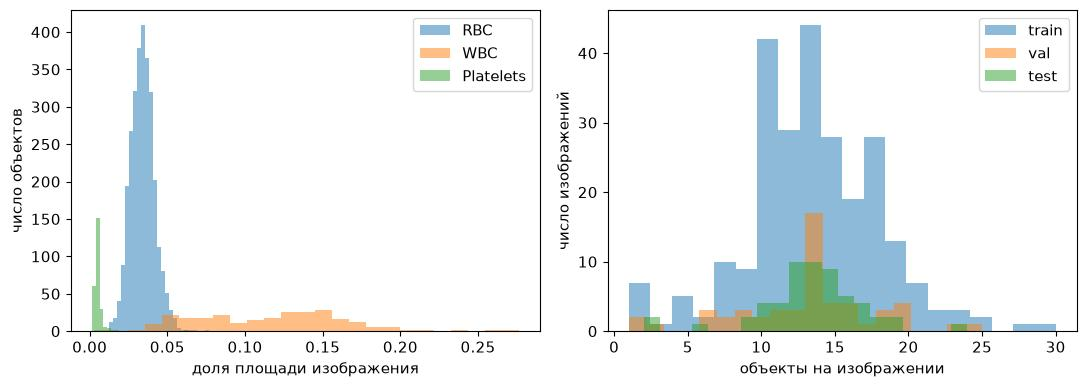

In [51]:
dataset_stats = {}
for split, recs in records.items():
    counts = np.bincount(np.concatenate([r['labels'] for r in recs]), minlength=len(CLASSES))
    objects = np.array([len(r['labels']) for r in recs])
    dataset_stats[split] = dict(images=len(recs), counts=dict(zip(CLASSES, counts.tolist())),
                                objects_mean=float(objects.mean()), objects_max=int(objects.max()))
    print(split, dataset_stats[split])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, name in enumerate(CLASSES):
    sizes = np.concatenate([(r['boxes'][r['labels'] == label, 2:] - r['boxes'][r['labels'] == label, :2])
                            / [r['width'], r['height']] for r in records['train']])
    axes[0].hist(np.prod(sizes, axis=1), bins=25, alpha=0.5, label=name)
axes[0].set(xlabel='доля площади изображения', ylabel='число объектов')
axes[0].legend()
for split, recs in records.items():
    axes[1].hist([len(r['labels']) for r in recs], bins=20, alpha=0.5, label=split)
axes[1].set(xlabel='объекты на изображении', ylabel='число изображений')
axes[1].legend()
plt.tight_layout()
plt.show()

rare_class = min(dataset_stats['train']['counts'], key=dataset_stats['train']['counts'].get)
common_class = max(dataset_stats['train']['counts'], key=dataset_stats['train']['counts'].get)


**Ответ:**

Использован [BCCD](https://github.com/Shenggan/BCCD_Dataset), лицензия MIT, исходная разметка VOC XML; версия данных зафиксирована commit `d272fb14cdff6e473fafeeeba32aba5f560e9e43`. Всего 364 изображения, разделённые при seed = 0 на train 254, val 54 и test 56. RBC — эритроциты, WBC — лейкоциты, Platelets — тромбоциты.

| Сплит | Изображения | RBC | WBC | Platelets | Среднее объектов на изображении |
|---|---:|---:|---:|---:|---:|
| train | 254 | 2916 | 258 | 257 | 13.51 |
| val | 54 | 593 | 56 | 54 | 13.02 |
| test | 56 | 644 | 58 | 50 | 13.43 |

В train 3431 объект, из них 85.0% — RBC; объектов этого класса примерно в 11.3 раза больше, чем WBC или Platelets. Максимум объектов на изображении train — 30: плотность и перекрытия затрудняют поиск границ, а тромбоциты заметно меньше остальных клеток по распределению площадей рамок. Удалены 2 рамки с неположительной площадью, выходящих за изображение рамок и точных дубликатов изображений не обнаружено. На BloodImage_00150.jpg видны похожие на RBC клетки без соответствующих рамок — возможная неполнота разметки.


## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [52]:
def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, координаты в [0, 1]
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    labels = np.asarray(labels, dtype=np.int64).reshape(-1)
    if len(boxes) != len(labels) or width <= 0 or height <= 0:
        raise ValueError('неверные размеры')
    center = (boxes[:, :2] + boxes[:, 2:]) / 2 / [width, height]
    size = (boxes[:, 2:] - boxes[:, :2]) / [width, height]
    return '\n'.join(f'{int(c)} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}'
                     for c, (cx, cy), (w, h) in zip(labels, center, size))


def from_yolo(text, width, height):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    rows = [line.split() for line in text.splitlines() if line.strip()]
    if not rows:
        return np.empty((0, 4), dtype=np.float32), np.empty(0, dtype=np.int64)
    values = np.asarray(rows, dtype=float)
    if values.shape[1] != 5 or width <= 0 or height <= 0:
        raise ValueError('неверный формат')
    center = values[:, 1:3] * [width, height]
    size = values[:, 3:5] * [width, height]
    boxes = np.concatenate([center - size / 2, center + size / 2], axis=1)
    return boxes.astype(np.float32), values[:, 0].astype(np.int64)


In [53]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')


to_yolo / from_yolo: ok


In [54]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    image_dir = YOLO_ROOT / 'images' / split
    label_dir = YOLO_ROOT / 'labels' / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    for record in recs:
        target = image_dir / Path(record['image']).name
        shutil.copy2(record['image'], target)
        (label_dir / (target.stem + '.txt')).write_text(
            to_yolo(record['boxes'], record['labels'], record['width'], record['height']), encoding='utf-8')


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True) # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val' # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())


path: /Users/macbook/Downloads/hw2_students/data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: RBC
  1: WBC
  2: Platelets



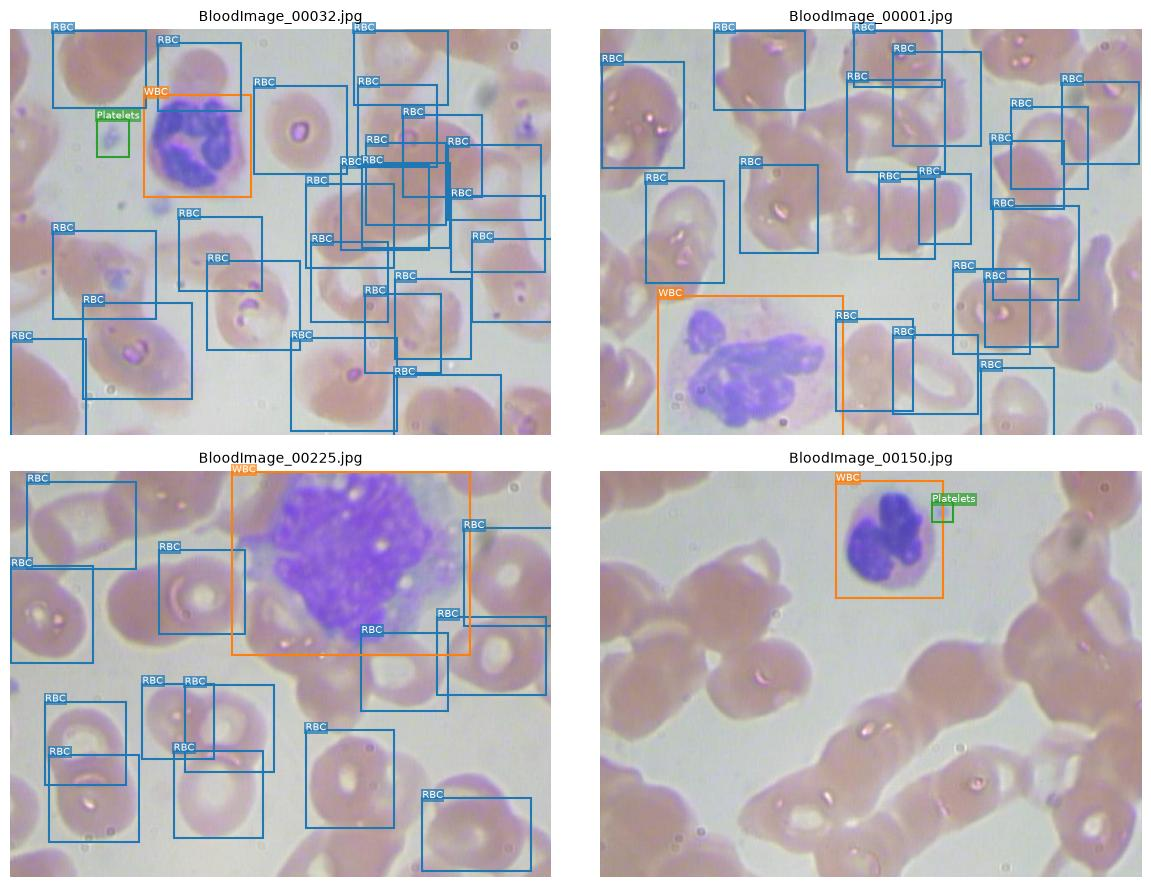

максимальная ошибка координат: 0.0003204345703125


In [55]:
roundtrip_max_error = 0.0
for split, recs in splits.items():
    for r in recs:
        text = (YOLO_ROOT / 'labels' / split / (Path(r['image']).stem + '.txt')).read_text()
        b, labels = from_yolo(text, r['width'], r['height'])
        assert np.array_equal(labels, r['labels'])
        assert np.allclose(b, r['boxes'], atol=1e-3)
        if len(b):
            roundtrip_max_error = max(roundtrip_max_error, float(np.max(np.abs(b-r['boxes']))))
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, r in zip(axes.flat, records['val'][:4]):
    text = (YOLO_ROOT / 'labels' / 'val' / (Path(r['image']).stem + '.txt')).read_text()
    boxes, labels = from_yolo(text, r['width'], r['height'])
    draw_boxes(ax, Image.open(r['image']), boxes, labels, CLASSES, title=Path(r['image']).name)
plt.tight_layout()
plt.show()
print('максимальная ошибка координат:', roundtrip_max_error)


**Ответ:**

Проверка записи и обратного чтения выполнена для всех 364 изображений; метки классов совпали, максимальное отклонение координат составило 0.000320 пикселя при допуске 0.001 пикселя. Открытые тесты to_yolo / from_yolo также прошли. Проверка выявляет потерю объектов, изменение координат и классов, но может пропустить две взаимно компенсирующие ошибки прямого и обратного преобразования. Поэтому показаны четыре изображения с восстановленными рамками: на них можно заметить перепутанные оси, неверный масштаб и ошибочные исходные границы.


---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

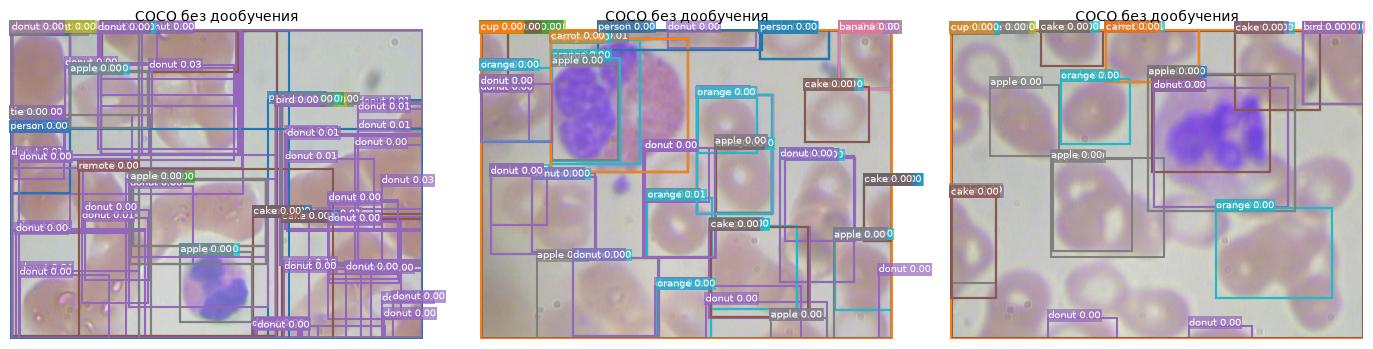

совпадающие классы: {} COCO mAP50: 0.0


In [56]:
coco_preds_raw = predict_records(model_coco, records[FINAL_SPLIT])
coco_class_map = {i: CLASSES.index(name) for i, name in model_coco.names.items() if name in CLASSES}
coco_preds = []
for p in coco_preds_raw:
    keep = np.array([int(label) in coco_class_map for label in p['labels']], dtype=bool)
    coco_preds.append(dict(boxes=p['boxes'][keep], scores=p['scores'][keep],
                           labels=np.array([coco_class_map[int(c)] for c in p['labels'][keep]], dtype=np.int64)))
coco_map50, _ = evaluate_map50(coco_preds, records[FINAL_SPLIT], len(CLASSES))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, r, p in zip(axes, records[FINAL_SPLIT][:3], coco_preds_raw[:3]):
    draw_boxes(ax, Image.open(r['image']), p['boxes'], p['labels'], model_coco.names,
               scores=p['scores'], title='COCO без дообучения')
plt.tight_layout()
plt.show()
print('совпадающие классы:', coco_class_map, 'COCO mAP50:', coco_map50)


In [57]:
def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей
    with Image.open(image_path) as image:
        width, height = image.size
    boxes, labels, scores = [], [], []
    for label, spec in heuristic_specs.items():
        count = spec['count']
        columns = math.ceil(math.sqrt(count))
        rows = math.ceil(count / columns)
        for j in range(count):
            cx = (j % columns + 0.5) / columns
            cy = (j // columns + 0.5) / rows
            w, h = spec['size']
            box = np.array([cx-w/2, cy-h/2, cx+w/2, cy+h/2])
            box[[0, 2]] = np.clip(box[[0, 2]], 0, 1)
            box[[1, 3]] = np.clip(box[[1, 3]], 0, 1)
            boxes.append(box * [width, height, width, height])
            labels.append(label)
            scores.append(1 / (j + 1))
    return dict(boxes=np.asarray(boxes, dtype=np.float32).reshape(-1, 4),
                labels=np.asarray(labels, dtype=np.int64), scores=np.asarray(scores, dtype=float))


In [58]:
heuristic_specs = {}
for label in range(len(CLASSES)):
    sizes = np.concatenate([(r['boxes'][r['labels'] == label, 2:] - r['boxes'][r['labels'] == label, :2])
                            / [r['width'], r['height']] for r in train_recs])
    counts = [int((r['labels'] == label).sum()) for r in train_recs]
    if len(sizes):
        heuristic_specs[label] = dict(size=sizes.mean(axis=0), count=max(1, round(float(np.mean(counts)))))
print({CLASSES[k]: v for k, v in heuristic_specs.items()})


{'RBC': {'size': array([    0.16302,     0.20894]), 'count': 11}, 'WBC': {'size': array([    0.30535,     0.36599]), 'count': 1}, 'Platelets': {'size': array([   0.064342,    0.082669]), 'count': 1}}


In [59]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
BASELINE


{'split': 'test',
 'coco_map50': 0.0,
 'heuristic_map50': 0.007043676417517002,
 'heuristic_ap50_per_class': {'RBC': 0.013460374783866982,
  'WBC': 0.007670654468684025,
  'Platelets': 0.0}}

**Ответ:**

Оба бейзлайна оценены на одном test из 56 изображений. Для COCO-модели mAP50 = 0.0000: классов RBC, WBC и Platelets среди её 80 классов нет, после сопоставления классов предсказания пусты; исходные предсказания до сопоставления показаны выше. Сеточная эвристика дала mAP50 = 0.00704: AP50 для RBC 0.01346, WBC 0.00767, Platelets 0.00000. Она использует средние размеры и число клеток только из train и не анализирует изображение, поэтому редкие совпадения сетки с крупными клетками случайны, а небольшие тромбоциты практически не локализуются.


---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [60]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}


In [61]:
TRAIN_ARGS = dict(epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, optimizer='AdamW',
                  lr0=0.001, lrf=0.01, weight_decay=0.0005, warmup_epochs=0 if FAST_MODE else 3,
                  patience=15, seed=SEED, deterministic=True, val=True, pretrained=True,
                  mosaic=0.0, mixup=0.0, degrees=0.0, translate=0.1, scale=0.2,
                  fliplr=0.5, flipud=0.5, hsv_h=0.01, hsv_s=0.2, hsv_v=0.2,
                  close_mosaic=0, plots=True, save=True, nms=False)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')


Ultralytics 8.4.216 🚀 Python-3.13.2 torch-2.15.0 MPS (Apple M3 Max)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.2, hsv_v=0.2, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=finetune, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_ma

/Users/macbook/.pyenv/versions/3.13.2/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/60      5.49G      1.238       2.62     0.0108        169        640: 100% ━━━━━━━━━━━━ 16/16 1.4it/s 11.3s0.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.6it/s 0.8s1.5s
                   all         54        703     0.0443      0.299     0.0782     0.0183

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/60       5.4G      1.087      1.679   0.009733        192        640: 0% ──────────── 0/16  0.8s

/Users/macbook/.pyenv/versions/3.13.2/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/60      5.38G      1.189      1.333     0.0103        194        640: 100% ━━━━━━━━━━━━ 16/16 2.5it/s 6.4s0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.7it/s 0.7s1.4s
                   all         54        703     0.0836       0.42      0.237       0.11

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/60      5.58G      1.205      1.242    0.01037        196        640: 0% ──────────── 0/16  1.0s

/Users/macbook/.pyenv/versions/3.13.2/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (95 outputs left out)

/Users/macbook/.pyenv/versions/3.13.2/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      51/60      5.62G     0.9429     0.4558   0.007776        200        640: 100% ━━━━━━━━━━━━ 16/16 2.6it/s 6.2s0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.0it/s 0.7s1.2s
                   all         54        703      0.846      0.924      0.933      0.642

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      52/60       5.4G      1.009     0.4885   0.008252        206        640: 0% ──────────── 0/16  0.7s

/Users/macbook/.pyenv/versions/3.13.2/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      52/60       5.4G     0.9427     0.4523   0.007843        191        640: 100% ━━━━━━━━━━━━ 16/16 2.6it/s 6.2s0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.0it/s 0.7s1.2s
                   all         54        703      0.853      0.923      0.931      0.637
EarlyStopping: Training stopped early as no improvement observed in last 15 epochs. Best results observed at epoch 37, best model saved as best.pt.
To update EarlyStopping(patience=15) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

52 epochs completed in 0.131 hours.
Optimizer stripped from /Users/macbook/Downloads/hw2_students/runs_hw2/finetune/weights/last.pt, 5.4MB
Optimizer stripped from /Users/macbook/Downloads/hw2_students/runs_hw2/finetune/weights/best.pt, 5.4MB

Validating /Users/macbook/Downloads/hw2_students/runs_hw2/finetune/weights/best.pt...
Ultralytics 8.4.216 🚀 Python-3.13.2 torch-2.15.0 MPS (

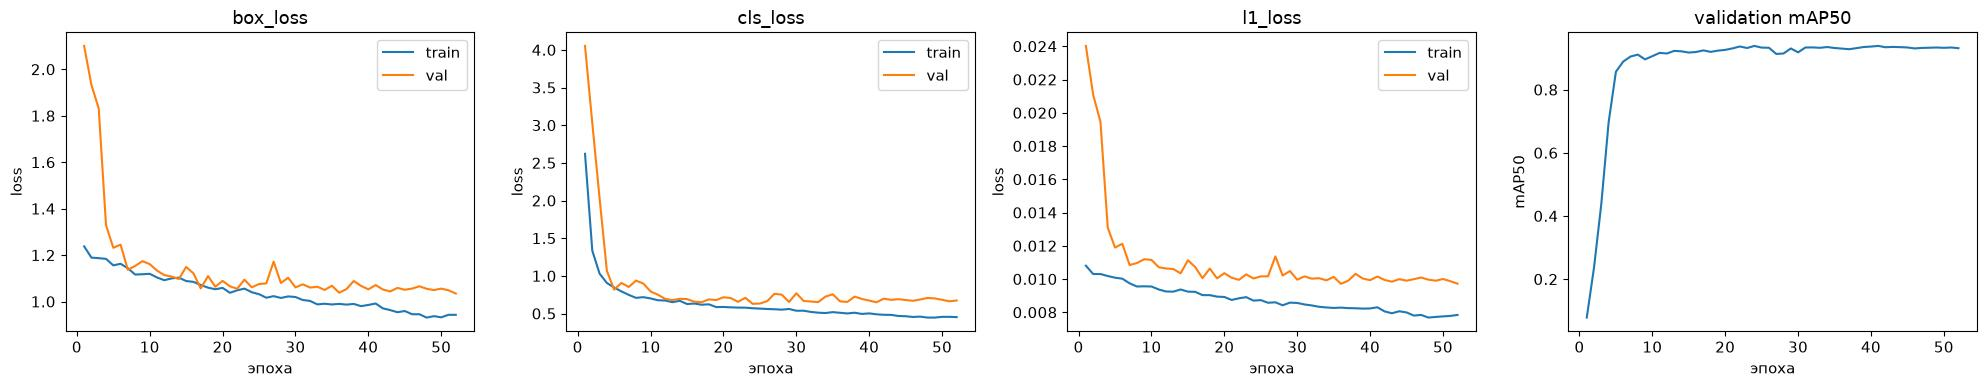

In [62]:
history = read_results(run_dir)
loss_names = [k[6:] for k in history if k.startswith('train/') and 'loss' in k]
fig, axes = plt.subplots(1, len(loss_names)+1, figsize=(5*(len(loss_names)+1), 4))
for ax, name in zip(axes, loss_names):
    for split in ('train', 'val'):
        key = f'{split}/{name}'
        if key in history:
            ax.plot(history['epoch'], history[key], label=split)
    ax.set(title=name, xlabel='эпоха', ylabel='loss')
    ax.legend()
axes[-1].plot(history['epoch'], history['metrics/mAP50(B)'])
axes[-1].set(title='validation mAP50', xlabel='эпоха', ylabel='mAP50')
plt.tight_layout()
plt.show()

last_map = history['metrics/mAP50(B)'][-1]
max_map = history['metrics/mAP50(B)'].max()
loss_trend = {name: (float(history[f'train/{name}'][-1]-history[f'train/{name}'][0]),
                     float(history[f'val/{name}'][-1]-history[f'val/{name}'][0])) for name in loss_names}


**Ответ:**

Заданы максимум 60 эпох, imgsz = 640, batch = 16, AdamW с lr0 = 0.001, lrf = 0.01, weight_decay = 0.0005, warmup_epochs = 3 и patience = 15. Небольшая предобученная модель дообучается с умеренным шагом и прогревом; 640 сохраняет детали мелких клеток, batch = 16 поместился в память M3 Max. Отражения и умеренные цветовые изменения подходят для микроскопии, mosaic отключён для сохранения исходного масштаба сцен.

Обучение заняло 474.0 с (7.90 мин) на Apple M3 Max / MPS и завершилось после 52 эпох: лучшая модель получена на 37-й, затем 15 эпох не было улучшения критерия ранней остановки. Train box/cls/l1 loss уменьшились с 1.2375/2.6204/0.01080 до 0.9427/0.4523/0.00784, val — с 2.1006/4.0524/0.02402 до 1.0343/0.6730/0.00972. К концу train loss продолжает снижаться, а val loss и качество выходят на плато; устойчивого роста val loss и сильного переобучения не видно. Лучший val mAP50–95 в истории — 0.65115 на 37-й эпохе; увеличение лимита эпох не обосновано, поскольку уже сработала ранняя остановка.


## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [63]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    kw.setdefault('nms', False)
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)


In [64]:
def pack_metrics(result):
    box = result.box
    per_class = {}
    for j, label in enumerate(box.ap_class_index):
        p, r, ap50, ap = box.class_result(j)
        per_class[CLASSES[int(label)]] = dict(precision=float(p), recall=float(r), map50=float(ap50), map50_95=float(ap))
    return dict(map50=float(box.map50), map50_95=float(box.map), precision=float(box.mp),
                recall=float(box.mr), per_class=per_class)

validation_result = val_metrics(best, 'val', 'eval_val', conf=0.001, plots=True)
VAL = pack_metrics(validation_result)
test_result = val_metrics(best, FINAL_SPLIT, 'eval_test', conf=0.001, plots=True)
FINAL = dict(split=FINAL_SPLIT, **pack_metrics(test_result))
print('val:', VAL)
print(FINAL_SPLIT, FINAL)


Ultralytics 8.4.216 🚀 Python-3.13.2 torch-2.15.0 MPS (Apple M3 Max)
YOLO26n summary (fused): 122 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 785.3±109.3 MB/s, size: 20.5 KB)
val: Scanning /Users/macbook/Downloads/hw2_students/data/yolo/labels/val.cache... 54 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 54/54 45.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 5.4it/s 0.7s0.2s
                   all         54        703      0.869      0.888      0.928      0.651
Speed: 0.1ms preprocess, 7.8ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /Users/macbook/Downloads/hw2_students/runs_hw2/eval_val
Ultralytics 8.4.216 🚀 Python-3.13.2 torch-2.15.0 MPS (Apple M3 Max)
YOLO26n summary (fused): 122 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 66.7±18.0 MB/s, size: 20.3 KB)
val

собственный mAP50: 0.9165213087960122 ultralytics: 0.928879753882928


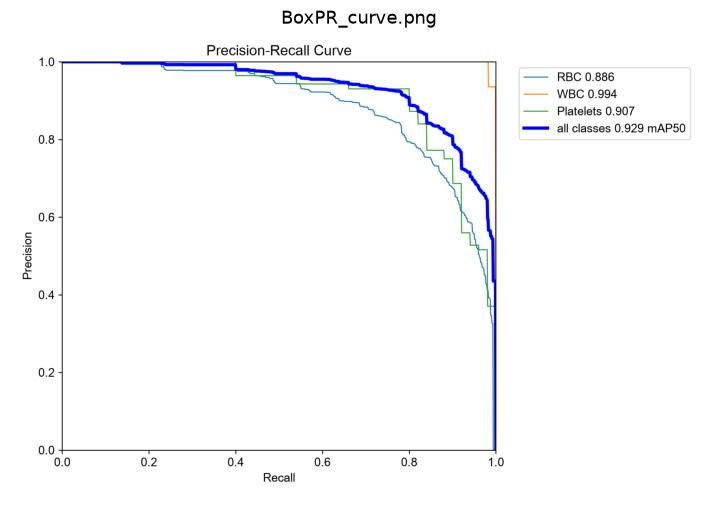

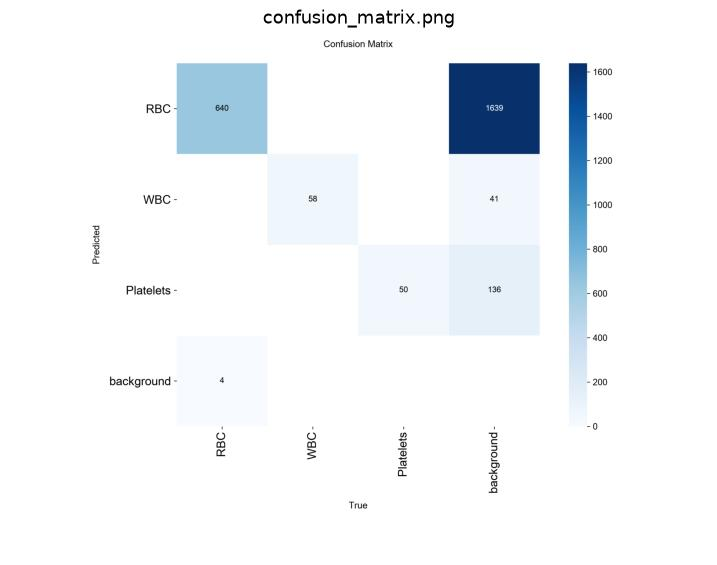

In [65]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}
final_predictions = predict_records(best, records[FINAL_SPLIT], conf=0.001)
map50_check, ap50_check = evaluate_map50(final_predictions, records[FINAL_SPLIT], len(CLASSES))
print('собственный mAP50:', map50_check, 'ultralytics:', FINAL['map50'])

for filename in ('BoxPR_curve.png', 'PR_curve.png', 'confusion_matrix.png'):
    path = Path(test_result.save_dir) / filename
    if path.exists():
        plt.figure(figsize=(9, 7))
        plt.imshow(plt.imread(path))
        plt.axis('off')
        plt.title(filename)
        plt.show()
worst_class = min(FINAL['per_class'], key=lambda k: FINAL['per_class'][k]['map50'])


**Ответ:**

Лучшие веса оценены на val и test:

| Сплит | mAP50 | mAP50–95 | Precision | Recall |
|---|---:|---:|---:|---:|
| val | 0.9278 | 0.6507 | 0.8693 | 0.8877 |
| test | 0.9289 | 0.6462 | 0.8889 | 0.8570 |

| Класс на test | Precision | Recall | AP50 | AP50–95 |
|---|---:|---:|---:|---:|
| RBC | 0.8561 | 0.7483 | 0.8856 | 0.6424 |
| WBC | 0.9910 | 0.9828 | 0.9944 | 0.7846 |
| Platelets | 0.8195 | 0.8400 | 0.9067 | 0.5115 |

По AP50 хуже RBC, а по более строгому AP50–95 — Platelets: вероятные причины — перекрытия и неполная разметка RBC, малый размер тромбоцитов и чувствительность их IoU к небольшому сдвигу рамки. mAP50–95 ниже mAP50, потому что усредняет IoU от 0.50 до 0.95 и строже оценивает границы.

В confusion matrix столбец background показывает лишние предсказания, строка background — пропуски; оси соответствуют истинному классу по X и предсказанному по Y. На приведённой матрице при низком conf = 0.001 у RBC 640 совпадений, 1639 лишних обнаружений и 4 пропуска; низкий порог сохраняет множество слабых рамок. P/R отчёта ultralytics усреднены по классам в выбранной точке PR-кривой, а матрица построена при conf = 0.001. Собственный mAP50 = 0.91652 против 0.92888 у ultralytics, разница −0.01236; причины — различия интерполяции AP, сопоставления предсказаний и препроцессинга.


---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [66]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25 # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)
    intersection = np.maximum(np.minimum(a[:, None, 2:], b[None, :, 2:]) -
                              np.maximum(a[:, None, :2], b[None, :, :2]), 0).prod(axis=2)
    area_a = np.maximum(a[:, 2:]-a[:, :2], 0).prod(axis=1)
    area_b = np.maximum(b[:, 2:]-b[:, :2], 0).prod(axis=1)
    union = area_a[:, None] + area_b[None, :] - intersection
    return np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    ious = box_iou_np(pred['boxes'], gt['boxes'])
    found = np.zeros(len(gt['labels']), dtype=bool)
    linked = np.zeros(len(gt['labels']), dtype=bool)
    categories = ['background'] * len(pred['labels'])
    for i in np.argsort(-np.asarray(pred['scores']), kind='stable'):
        same = np.asarray(gt['labels']) == pred['labels'][i]
        candidates = np.flatnonzero(same & ~found & (ious[i] >= iou_hit))
        if len(candidates):
            j = candidates[np.argmax(ious[i, candidates])]
            categories[i] = 'tp'
            found[j] = True
            linked[j] = True
            continue
        candidates = np.flatnonzero(~same & (ious[i] >= iou_hit))
        if len(candidates):
            j = candidates[np.argmax(ious[i, candidates])]
            categories[i] = 'class'
            linked[j] = True
            continue
        candidates = np.flatnonzero(same & ~found & (ious[i] >= iou_loc) & (ious[i] < iou_hit))
        if len(candidates):
            j = candidates[np.argmax(ious[i, candidates])]
            categories[i] = 'localization'
            linked[j] = True
    return categories, np.flatnonzero(~found & ~linked).tolist()


In [67]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')


box_iou_np / categorize_predictions: ok


категории: {'tp': 586, 'class': 0, 'localization': 21, 'background': 211, 'missed': 103}
доли среди ошибок: {'class': 0.0, 'localization': 0.0626865671641791, 'background': 0.6298507462686567, 'missed': 0.3074626865671642}
по классам (предсказанные, для missed истинные): {'RBC': {'tp': 479, 'class': 0, 'localization': 21, 'background': 197, 'missed': 100}, 'WBC': {'tp': 56, 'class': 0, 'localization': 0, 'background': 1, 'missed': 0}, 'Platelets': {'tp': 51, 'class': 0, 'localization': 0, 'background': 13, 'missed': 3}}


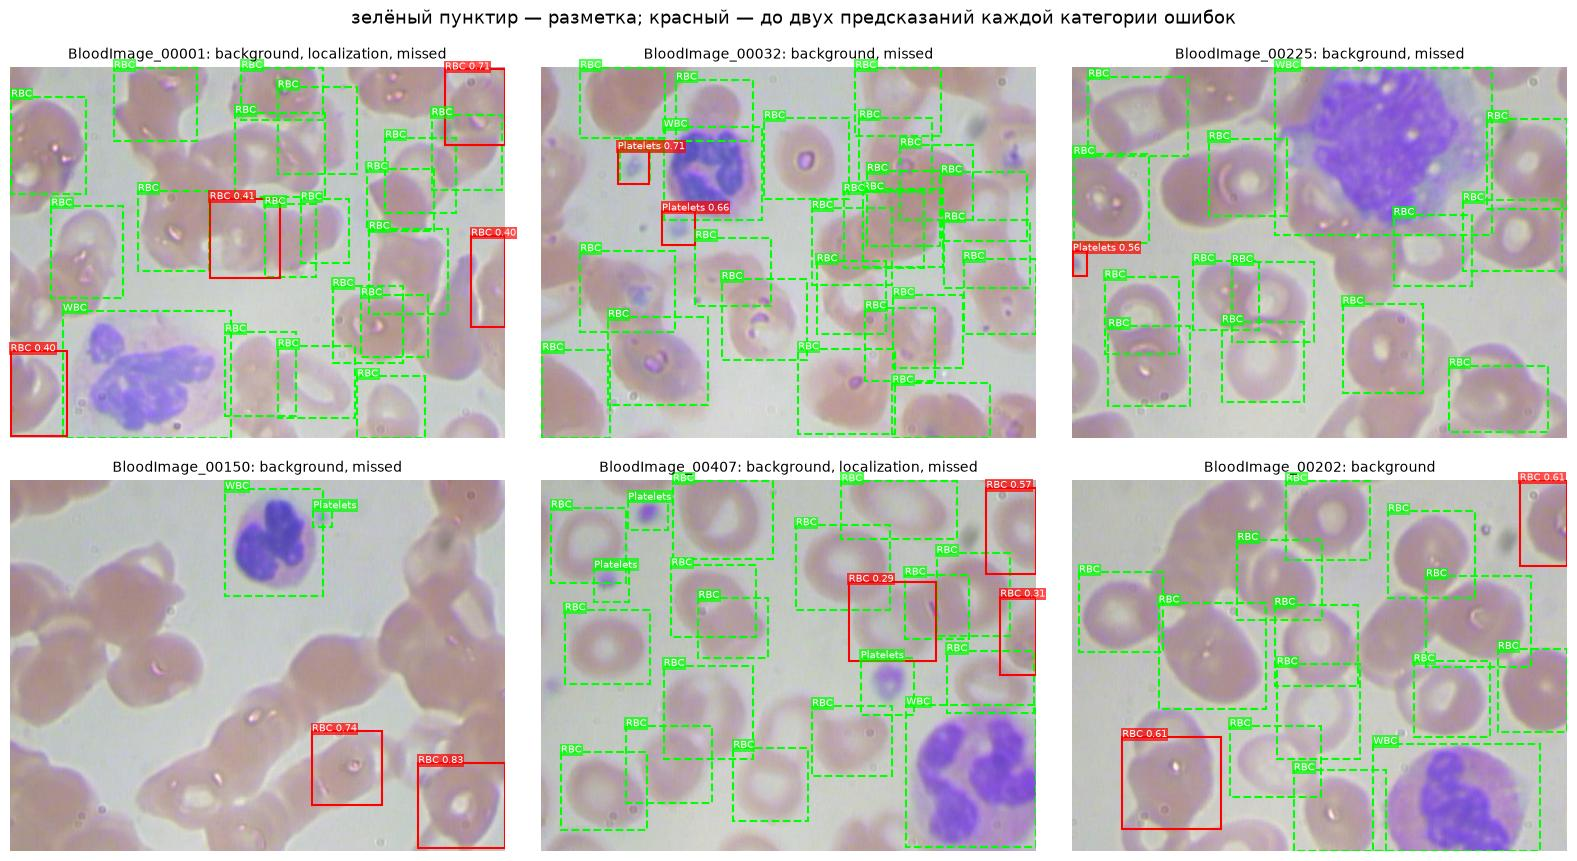

In [68]:
val_predictions = predict_records(best, records['val'], conf=CONF_ERRORS)
ERRORS = dict.fromkeys(ERROR_TYPES, 0)
errors_by_class = {name: dict.fromkeys(ERROR_TYPES, 0) for name in CLASSES}
error_cases = []
for r, p in zip(records['val'], val_predictions):
    cats, missed = categorize_predictions(p, r)
    for i, category in enumerate(cats):
        ERRORS[category] += 1
        errors_by_class[CLASSES[int(p['labels'][i])]][category] += 1
    for j in missed:
        ERRORS['missed'] += 1
        errors_by_class[CLASSES[int(r['labels'][j])]]['missed'] += 1
    categories = {c for c in cats if c != 'tp'} | ({'missed'} if missed else set())
    if categories:
        error_cases.append((r, p, categories))
n_errors = sum(v for k, v in ERRORS.items() if k != 'tp')
error_shares = {k: v/max(n_errors, 1) for k, v in ERRORS.items() if k != 'tp'}
print('категории:', ERRORS)
print('доли среди ошибок:', error_shares)
print('по классам (предсказанные, для missed истинные):', errors_by_class)
selected = []
covered = set()
for case in sorted(error_cases, key=lambda x: len(x[2]), reverse=True):
    if case[2] - covered:
        selected.append(case)
        covered |= case[2]
for case in error_cases:
    if len(selected) >= 6:
        break
    if not any(case[0]['image'] == c[0]['image'] for c in selected):
        selected.append(case)
assert len(selected) >= 5, 'для пяти примеров нужны ошибки хотя бы на пяти изображениях; проверьте порог'
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (r, p, categories) in zip(axes.flat, selected[:6]):
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES,
               color='lime', linestyle='--')
    cats, _ = categorize_predictions(p, r)
    visible = []
    for category in ('class', 'localization', 'background'):
        candidates = [i for i, c in enumerate(cats) if c == category]
        visible.extend(sorted(candidates, key=lambda i: p['scores'][i], reverse=True)[:2])
    visible = np.asarray(visible, dtype=np.int64)
    draw_boxes(ax, None, p['boxes'][visible], p['labels'][visible], CLASSES, p['scores'][visible], color='red',
               title=Path(r['image']).stem + ': ' + ', '.join(sorted(categories)))
plt.suptitle('зелёный пунктир — разметка; красный — до двух предсказаний каждой категории ошибок')
plt.tight_layout()
plt.show()

main_error = max(error_shares, key=error_shares.get)
remedies = {'missed': 'проверить полноту разметки, увеличить число примеров редких и мелких объектов',
            'background': 'добавить сложные отрицательные примеры и подобрать conf на val',
            'class': 'проверить метки классов и добавить примеры похожих клеток',
            'localization': 'уточнить границы разметки и проверить более высокое разрешение'}


**Ответ:**

При conf = 0.25 на val получены 586 TP, 211 background, 103 missed, 21 localization и 0 class. Всего 335 ошибок: лишние рамки составляют 63.0%, пропуски 30.7%, неточная локализация 6.3%; ошибок класса не обнаружено. Главные трудности связаны с RBC: 197 из 211 лишних рамок, 100 из 103 пропусков и все 21 ошибки локализации.

Шесть показанных изображений содержат разные наблюдаемые категории ошибок; для читаемости отображено до двух самых уверенных предсказаний каждой категории, но подсчёт выполнен по всем рамкам. В BloodImage_00001 и BloodImage_00407 видны неточные рамки RBC и перекрывающиеся клетки, в BloodImage_00032 и BloodImage_00225 — лишние рамки тромбоцитов. На BloodImage_00150 уверенные рамки RBC попадают на похожие на эритроциты клетки без зелёных рамок: часть формальных background может быть неполной разметкой, а не ошибкой детектора. Для уменьшения главной категории сначала следует проверить полноту разметки и дубликаты рамок, затем добавить сложные отрицательные примеры.


## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [69]:
ablation_args = dict(TRAIN_ARGS)
ablation_args['imgsz'] = IMGSZ // 2
model_ablation, ablation_seconds, ablation_dir = train_yolo('ablation_imgsz', **ablation_args)
ablation_best = YOLO(ablation_dir / 'weights' / 'best.pt')
ablation_result = ablation_best.val(data=str(DATA_YAML), split='val', imgsz=ablation_args['imgsz'],
                                   batch=BATCH, device=DEVICE, workers=WORKERS, conf=0.001,
                                   project=str(RUNS.resolve()), name='eval_ablation', exist_ok=True,
                                   verbose=False, plots=False, nms=False)
ABLATION = dict(parameter='imgsz', split='val',
                main=dict(value=IMGSZ, map50=VAL['map50'], map50_95=VAL['map50_95'], seconds=RUN_TIMES['train']),
                alternative=dict(value=ablation_args['imgsz'], map50=float(ablation_result.box.map50),
                                 map50_95=float(ablation_result.box.map), seconds=ablation_seconds))
print(ABLATION)

delta_ap = ABLATION['alternative']['map50'] - ABLATION['main']['map50']


Ultralytics 8.4.216 🚀 Python-3.13.2 torch-2.15.0 MPS (Apple M3 Max)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.2, hsv_v=0.2, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=ablation_imgsz, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, over

/Users/macbook/.pyenv/versions/3.13.2/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/60      3.42G      1.381      2.669    0.01224        169        320: 100% ━━━━━━━━━━━━ 16/16 3.7it/s 4.3s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.4it/s 0.8s1.6s
                   all         54        703      0.449      0.151      0.111     0.0563

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/60      3.38G      1.239      2.071    0.01076        235        320: 6% ╸─────────── 1/16 2.3it/s 0.8s<6.6s

/Users/macbook/.pyenv/versions/3.13.2/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/60      3.38G      1.251      1.764    0.01097        194        320: 100% ━━━━━━━━━━━━ 16/16 5.1it/s 3.2s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.3it/s 0.6s1.0s
                   all         54        703      0.485       0.11      0.129     0.0627

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/60      3.38G       1.28      1.475    0.01103        231        320: 6% ╸─────────── 1/16 2.5it/s 0.7s<6.0s

/Users/macbook/.pyenv/versions/3.13.2/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (95 outputs left out)

/Users/macbook/.pyenv/versions/3.13.2/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      51/60      3.39G      1.041     0.5831   0.008725        200        320: 100% ━━━━━━━━━━━━ 16/16 5.3it/s 3.0s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.2it/s 0.6s1.1s
                   all         54        703      0.874       0.89      0.929      0.625

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      52/60      3.39G      1.078     0.5914   0.008605        232        320: 6% ╸─────────── 1/16 2.4it/s 0.7s<6.2s

/Users/macbook/.pyenv/versions/3.13.2/lib/python3.13/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      52/60      3.39G      1.043     0.5842   0.008766        191        320: 100% ━━━━━━━━━━━━ 16/16 5.3it/s 3.0s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.1it/s 0.7s1.2s
                   all         54        703      0.863      0.885      0.928       0.63
EarlyStopping: Training stopped early as no improvement observed in last 15 epochs. Best results observed at epoch 37, best model saved as best.pt.
To update EarlyStopping(patience=15) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.

52 epochs completed in 0.067 hours.
Optimizer stripped from /Users/macbook/Downloads/hw2_students/runs_hw2/ablation_imgsz/weights/last.pt, 5.4MB
Optimizer stripped from /Users/macbook/Downloads/hw2_students/runs_hw2/ablation_imgsz/weights/best.pt, 5.4MB

Validating /Users/macbook/Downloads/hw2_students/runs_hw2/ablation_imgsz/weights/best.pt...
Ultralytics 8.4.216 🚀 Python-3.13.2 

**Ответ:**

Изменён только imgsz: 640 → 320, остальные заданные настройки, исходные веса, seed и разбиение одинаковы. Оба обучения завершились после 52 эпох, лучшие веса — на 37-й. При 640 val mAP50/mAP50–95 = 0.92776/0.65068, время 474.0 с; при 320 — 0.93038/0.63855, время 243.5 с: ускорение 1.95 раза, изменение mAP50 +0.00262, mAP50–95 −0.01213. В этом запуске при уменьшении разрешения обнаружение сохранилось, а точная локализация немного ухудшилась; для скорости вариант 320 оправдан, для более точных рамок предпочтителен 640.


## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:**

YOLO26n дообучена на 254 изображениях BCCD с проверкой на 54 изображениях val и итоговой оценкой на 56 изображениях test. На test получены mAP50 = 0.9289 и mAP50–95 = 0.6462, тогда как COCO-модель дала 0.0000, а сеточная эвристика — 0.00704 mAP50. Лучше всего распознаются WBC с AP50 = 0.9944, самый низкий AP50 у RBC — 0.8856. Основное обучение заняло 474.0 с на M3 Max / MPS и остановилось на 52-й эпохе с лучшими весами 37-й эпохи.

Основная категория ошибок на val при conf = 0.25 — background: 211 случаев, или 63.0% всех ошибок. Уменьшение imgsz до 320 сократило обучение до 243.5 с, почти сохранив mAP50, но снизило mAP50–95 с 0.6507 до 0.6386. Ограничения — небольшой val/test, один seed и возможная неполнота разметки. Для улучшения качества стоит проверить и дополнить разметку RBC.


### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [70]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])


Сохранено: ['best.pt', 'bonus_metrics.json', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [71]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError


**Ответ:**

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [72]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError


**Ответ:**


## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

Ultralytics 8.4.216 🚀 Python-3.13.2 torch-2.15.0 MPS (Apple M3 Max)
YOLO26n summary (fused): 122 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1278.4±272.7 MB/s, size: 30.2 KB)
val: Scanning /Users/macbook/Downloads/hw2_students/data/corruptions/dark/labels/val... 54 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 54/54 3.9Kit/s 0.0s
val: New cache created: /Users/macbook/Downloads/hw2_students/data/corruptions/dark/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 7.2it/s 0.6s0.2s
                   all         54        703      0.611      0.692      0.647      0.397
Speed: 0.1ms preprocess, 5.9ms inference, 0.0ms loss, 1.0ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.13.2 torch-2.15.0 MPS (Apple M3 Max)
YOLO26n summary (fused): 122 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 

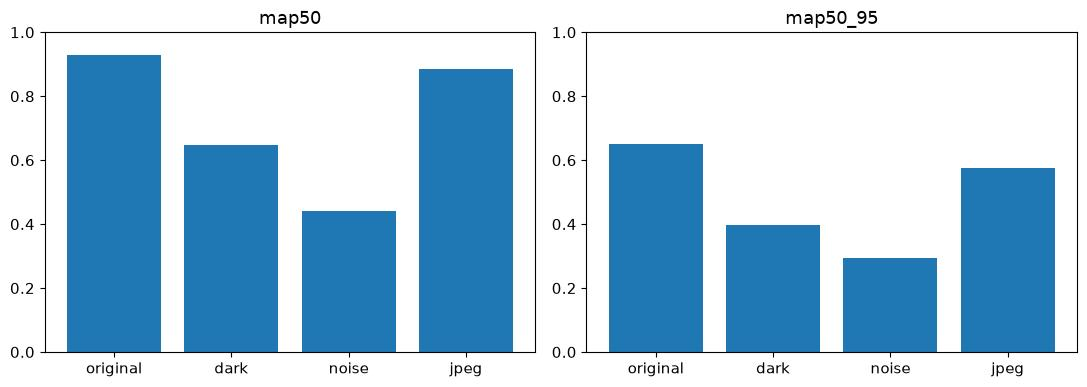

In [73]:
if '6.3' in BONUS_TASKS:
    corruption_root = DATA_ROOT / 'corruptions'
    shutil.rmtree(corruption_root, ignore_errors=True)
    corruption_results = {'original': VAL}
    rng_corrupt = np.random.default_rng(SEED)
    for corruption in ('dark', 'noise', 'jpeg'):
        folder = corruption_root / corruption
        image_dir = folder / 'images' / 'val'
        label_dir = folder / 'labels' / 'val'
        image_dir.mkdir(parents=True)
        label_dir.mkdir(parents=True)
        for r in records['val']:
            with Image.open(r['image']) as image:
                array = np.asarray(image.convert('RGB'))
            target = image_dir / Path(r['image']).name
            if corruption == 'dark':
                Image.fromarray((array * 0.4).astype(np.uint8)).save(target, quality=95)
            elif corruption == 'noise':
                noise = rng_corrupt.normal(0, 25, array.shape)
                Image.fromarray(np.clip(array.astype(float) + noise, 0, 255).astype(np.uint8)).save(target, quality=95)
            else:
                Image.fromarray(array).save(target, quality=10)
            source = YOLO_ROOT / 'labels' / 'val' / (Path(r['image']).stem + '.txt')
            shutil.copy2(source, label_dir / source.name)
        yaml_path = folder / 'data.yaml'
        yaml_path.write_text(f'path: {folder.resolve().as_posix()}\ntrain: images/val\nval: images/val\nnames:\n'
                             + ''.join(f'  {i}: {name}\n' for i, name in enumerate(CLASSES)))
        result = YOLO(run_dir / 'weights' / 'best.pt').val(
            data=str(yaml_path), split='val', imgsz=IMGSZ, batch=BATCH, device=DEVICE,
            workers=WORKERS, conf=0.001, project=str(RUNS.resolve()), name=f'shift_{corruption}',
            exist_ok=True, verbose=False, plots=False, nms=False)
        corruption_results[corruption] = pack_metrics(result)
    print(json.dumps(corruption_results, ensure_ascii=False, indent=2))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axes, ('map50', 'map50_95')):
        ax.bar(list(corruption_results), [v[metric] for v in corruption_results.values()])
        ax.set(title=metric, ylim=(0, 1))
    plt.tight_layout()
    plt.show()

if '6.3' in BONUS_TASKS:
    worst_shift = min(('dark', 'noise', 'jpeg'), key=lambda k: corruption_results[k]['map50'])
    shift_changes = {k: round(v['map50']-VAL['map50'], 4) for k, v in corruption_results.items() if k != 'original'}
    per_class_shift = {c: round(corruption_results[worst_shift]['per_class'].get(c, {}).get('map50', 0)
                               - VAL['per_class'].get(c, {}).get('map50', 0), 4) for c in CLASSES}


**Ответ:**

На тех же 54 изображениях val проверены яркость ×0.4, гауссов шум σ = 25 и JPEG quality = 10; размеры и рамки сохранены.

| Данные | mAP50 | mAP50–95 | Изменение mAP50 относительно оригинала |
|---|---:|---:|---:|
| Оригинал | 0.9278 | 0.6507 | 0.0000 |
| Затемнение | 0.6470 | 0.3968 | −0.2808 |
| Гауссов шум | 0.4411 | 0.2944 | −0.4866 |
| JPEG | 0.8840 | 0.5752 | −0.0437 |

Сильнее всего влияет шум: AP50 RBC падает с 0.8566 до 0.1466, Platelets — с 0.9316 до 0.1883, а WBC меняется с 0.9950 до 0.9885. Шум скрывает мелкие детали тромбоцитов и границы RBC; крупные WBC с выраженной структурой устойчивее в этом эксперименте. Для устойчивости к шуму можно добавить гауссов шум при обучении, к затемнению — изменения яркости, к сжатию — JPEG-аугментацию.


## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [74]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError


**Ответ:**


## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [75]:
if '6.5' in BONUS_TASKS:
    threshold_results = []
    threshold_models = {mode: YOLO(run_dir / 'weights' / 'best.pt') for mode in (True, False)}
    threshold_predictions = {}
    for end2end, detector in threshold_models.items():
        for confidence in (0.001, 0.1, 0.25, 0.5):
            for nms_iou in (0.3, 0.7):
                result = detector.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=BATCH,
                                      device=DEVICE, workers=WORKERS, conf=confidence, iou=nms_iou,
                                      end2end=end2end, nms=not end2end, project=str(RUNS.resolve()),
                                      name=f'threshold_{end2end}_{confidence}_{nms_iou}',
                                      exist_ok=True, verbose=False, plots=False)
                predictions = predict_records(detector, records['val'], conf=confidence,
                                              iou=nms_iou, end2end=end2end, nms=not end2end)
                counts = Counter(tp=0, fp=0, fn=0)
                for r, p in zip(records['val'], predictions):
                    cats, _ = categorize_predictions(p, r)
                    tp = cats.count('tp')
                    counts['tp'] += tp
                    counts['fp'] += len(cats)-tp
                    counts['fn'] += len(r['labels'])-tp
                precision = counts['tp']/max(counts['tp']+counts['fp'], 1)
                recall = counts['tp']/max(counts['tp']+counts['fn'], 1)
                f1 = 2*precision*recall/max(precision+recall, 1e-12)
                threshold_results.append(dict(end2end=end2end, conf=confidence, iou=nms_iou,
                                              precision=precision, recall=recall, f1=f1,
                                              map50=float(result.box.map50), map50_95=float(result.box.map)))
                assert bool(detector.predictor.model.end2end) == end2end
                threshold_predictions[(end2end, confidence, nms_iou)] = predictions
    print('end2end conf iou precision recall f1 mAP50 mAP50-95')
    for row in threshold_results:
        print(row['end2end'], *(f'{row[k]:.4f}' for k in ('conf','iou','precision','recall','f1','map50','map50_95')))
    threshold_choice = max((r for r in threshold_results if r['end2end']), key=lambda r: r['f1'])
    differences_e2e = []
    for confidence in (0.001, 0.1, 0.25, 0.5):
        pa = threshold_predictions[(True, confidence, 0.3)]
        pb = threshold_predictions[(True, confidence, 0.7)]
        same = all(a['boxes'].shape == b['boxes'].shape and np.allclose(a['boxes'], b['boxes'])
                   and np.array_equal(a['labels'], b['labels']) and np.allclose(a['scores'], b['scores'])
                   for a, b in zip(pa, pb))
        differences_e2e.append(dict(conf=confidence, identical=bool(same)))
    print('выбранный порог:', threshold_choice)
    print('проверка влияния iou в end-to-end:', differences_e2e)

if '6.5' in BONUS_TASKS:
    bonus_metrics = dict(tasks=sorted(BONUS_TASKS), corruptions=corruption_results,
                         thresholds=threshold_results, selected_threshold=threshold_choice,
                         end2end_iou_check=differences_e2e)
    (artifact_dir / 'bonus_metrics.json').write_text(
        json.dumps(json_ready(bonus_metrics), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.
Ultralytics 8.4.216 🚀 Python-3.13.2 torch-2.15.0 MPS (Apple M3 Max)
YOLO26n summary (fused): 122 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 794.9±71.3 MB/s, size: 20.2 KB)
val: Scanning /Users/macbook/Downloads/hw2_students/data/yolo/labels/val.cache... 54 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 54/54 45.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 14.1it/s 0.3s.6s
                   all         54        703      0.869      0.888      0.928      0.651
Speed: 0.1ms preprocess, 1.0ms inference, 0.0ms loss, 1.0ms postprocess per image
WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.
WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.
WARNING ⚠

**Ответ:**

Проверены conf ∈ {0.001, 0.1, 0.25, 0.5} и iou ∈ {0.3, 0.7} отдельно для end-to-end и one2many + NMS. Для стандартной end-to-end ветки выбран conf = 0.25 по максимальному F1 на val: precision = 0.7164, recall = 0.8336, F1 = 0.7705; при conf = 0.5 precision растёт до 0.8242, но recall снижается до 0.7070 и F1 до 0.7611. P/R рассчитаны при фиксированном conf и IoU сопоставления 0.5.

В end-to-end смена iou с 0.3 на 0.7 дала идентичные рамки и оценки при всех четырёх conf: подавления NMS здесь нет. В one2many при conf = 0.25 изменение iou меняет P/R с 0.6762/0.8706 на 0.6663/0.8748; лучший F1 этой ветки в сетке — 0.7863 при conf = 0.5 и iou = 0.7.

mAP интегрирует PR-кривую и мало зависит от изменения достаточно низкого порога, пока сохраняются значимые предсказания; для всей проверенной сетки независимости нет: в end-to-end mAP50 уменьшается с 0.9278 при conf = 0.001 до 0.8054 при conf = 0.5 из-за отсечения предсказаний и ограничения recall. Подбор выполнен только по val, итоговый test из 4.2 остаётся оценённым при conf = 0.001.
